In [1]:

from pathlib import Path

# Locate the project's raw flight logs
raw_dir = Path(r"D:\Drone-research\data\raw")

# Find all ArduPilot BIN files
log_files = sorted(
    file for file in raw_dir.rglob("*")
    if file.is_file() and file.suffix.lower() == ".bin"
)

print("Directory exists:", raw_dir.exists())
print("Total flight logs:", len(log_files))

for i, file in enumerate(log_files, start=1):
    size_mb = file.stat().st_size / (1024 ** 2)
    print(f"{i}. {file.name} | {size_mb:.2f} MB")


Directory exists: True
Total flight logs: 102
1. 1 01-01-1980 05-30-00 AM.bin | 0.50 MB
2. 10 01-01-1980 05-30-00 AM.bin | 0.75 MB
3. 100 01-01-1980 05-30-00 AM.bin | 0.28 MB
4. 101 01-01-1980 05-30-00 AM.bin | 0.29 MB
5. 102 01-01-1980 05-30-00 AM.bin | 0.29 MB
6. 11 01-01-1980 05-30-00 AM.bin | 4.91 MB
7. 12 01-01-1980 05-30-00 AM.bin | 0.37 MB
8. 13 01-01-1980 05-30-00 AM.bin | 1.62 MB
9. 14 01-01-1980 05-30-00 AM.bin | 1.16 MB
10. 1980-01-09 18-01-22.bin | 1.23 MB
11. 1980-01-10 18-20-39.bin | 5.46 MB
12. 1980-01-10 19-03-03.bin | 3.78 MB
13. 1980-01-11 11-17-24.bin | 1.00 MB
14. 1980-01-11 18-45-27.bin | 6.77 MB
15. 1980-01-11 18-54-46.bin | 8.34 MB
16. 2 01-01-1980 05-30-00 AM.bin | 0.83 MB
17. 20 01-01-1980 05-30-00 AM.bin | 0.56 MB
18. 2026-05-14 18-47-26.bin | 1.40 MB
19. 2026-05-15 18-42-30.bin | 2.77 MB
20. 2026-05-19 11-10-00.bin | 1.69 MB
21. 2026-05-19 11-44-09.bin | 1.34 MB
22. 2026-05-22 11-00-24.bin | 1.32 MB
23. 2026-05-22 11-01-15.bin | 1.43 MB
24. 2026-05-22 11-15-1

In [2]:
from pymavlink import mavutil
selected_log = raw_dir / "2026-07-02 18-37-42.bin"

log = mavutil.mavlink_connection(
    str(selected_log)
)

message_counts = {}

while True:
    msg = log.recv_match()

    if msg is None:
        break

    msg_type = msg.get_type()

    message_counts[msg_type] = (
        message_counts.get(msg_type, 0) + 1
    )

print("Total message types:", len(message_counts))
print("\nMessage types and counts:\n")

for msg_type, count in sorted(message_counts.items()):
    print(f"{msg_type}:{count}")

Total message types: 55

Message types and counts:

AHR2:11437
ARM:18
ATT:11437
BARO:11437
CMD:1
CTRL:11436
CTUN:11437
D32:9
DSF:1141
DU32:1144
ERR:7
EV:70
FILE:10397
FMT:171
FMTU:171
GPA:5718
GPS:5718
IMU:28591
MAG:22866
MODE:16
MOTB:11437
MSG:28
MULT:15
ORGN:20
PARM:1224
PM:114
POS:11437
POWR:11433
PSCD:11437
PSCE:11150
PSCN:11150
RATE:11437
RCIN:11437
RCO2:11437
RCOU:11437
SRTL:136
STAK:11344
TERR:1144
UBX2:229
UNIT:34
VER:1
VIBE:11437
XKF1:11437
XKF2:11437
XKF3:11437
XKF4:11437
XKF5:11437
XKFM:1011
XKFS:11437
XKQ:11437
XKT:224
XKV1:2288
XKV2:2288
XKY0:10364
XKY1:10364


In [3]:
from pymavlink import mavutil

# reopen the file because the previous cell already read to the end of the log

log = mavutil.mavlink_connection(
    str(selected_log)
)

# message types that we want to inspect
targe_types = [
    "ATT", "IMU", "GPS", "BARO", "VIBE", "RCOU", "RCIN", "MODE", "ERR", "POWR"
]

found = {}

while len(found)<len(targe_types):
    msg = log.recv_match()

    if msg is None:
        break

    msg_type = msg.get_type()
    if msg_type in targe_types and msg_type not in found:
        found[msg_type] = msg.to_dict()

# Display fields and example values
for msg_type in targe_types:
    print(f"\n{'=' * 45}")
    print(f"MESSAGE TYPE: {msg_type}")
    print("=" * 45)

    if msg_type in found:
        for field, value in found[msg_type].items():
            print(f"{field}: {value}")
    else:
        print("Not found in this log")


MESSAGE TYPE: ATT
mavpackettype: ATT
TimeUS: 23845225
DesRoll: 0.0
Roll: 1.24
DesPitch: 0.0
Pitch: -0.47
DesYaw: 0.03
Yaw: 0.03
ErrRP: 0.0
ErrYaw: 1.0
AEKF: 3

MESSAGE TYPE: IMU
mavpackettype: IMU
TimeUS: 23825000
I: 0
GyrX: -0.0009286139393225312
GyrY: -0.0013944089878350496
GyrZ: 0.0016778368735685945
AccX: -0.05512865260243416
AccY: -0.20435377955436707
AccZ: -9.772649765014648
EG: 0
EA: 0
T: 32.49399948120117
GH: 1
AH: 1
GHz: 1603
AHz: 1603

MESSAGE TYPE: GPS
mavpackettype: GPS
TimeUS: 23945068
I: 0
Status: 3
GMS: 392880800
GWk: 2425
NSats: 24
HDop: 1.18
Lat: 22.2500655
Lng: 84.9027043
Alt: 222.71
Spd: 0.018000001087784767
GCrs: 0.0
VZ: 0.03700000047683716
Yaw: 0.0
U: 1

MESSAGE TYPE: BARO
mavpackettype: BARO
TimeUS: 23844996
I: 0
Alt: 0.3834322392940521
Press: 97617.0
Temp: 31.19
CRt: 0.09724728018045425
SMS: 23844
Offset: 0.0
GndTemp: 29.849998474121094
Health: 1

MESSAGE TYPE: VIBE
mavpackettype: VIBE
TimeUS: 23845673
IMU: 0
VibeX: 0.021572336554527283
VibeY: 0.0154715878888964

In [4]:
from pymavlink import mavutil

log = mavutil.mavlink_connection(str(selected_log))

first_time = None
last_time = None

for msg in iter(lambda:log.recv_match(), None):
    data = msg.to_dict()
    timestamp = data.get("TimeUS")

    if timestamp is None:
        continue

    if first_time is None or timestamp < first_time:
        first_time = timestamp

    if last_time is None or timestamp > last_time:
        last_time = timestamp

if first_time is not None and last_time is not None:
    duration_seconds = (last_time - first_time) / 1_000_000

    print(f"First timestamp: {first_time} μs")
    print(f"Last timestamp: {last_time} μs")
    print(f"Recording duration: {duration_seconds:.2f} seconds")
    print(f"Recording duration: {duration_seconds / 60:.2f} minutes")
else:
    print("No TimeUS timestamps found:")

First timestamp: 23815933 μs
Last timestamp: 1325147772 μs
Recording duration: 1301.33 seconds
Recording duration: 21.69 minutes


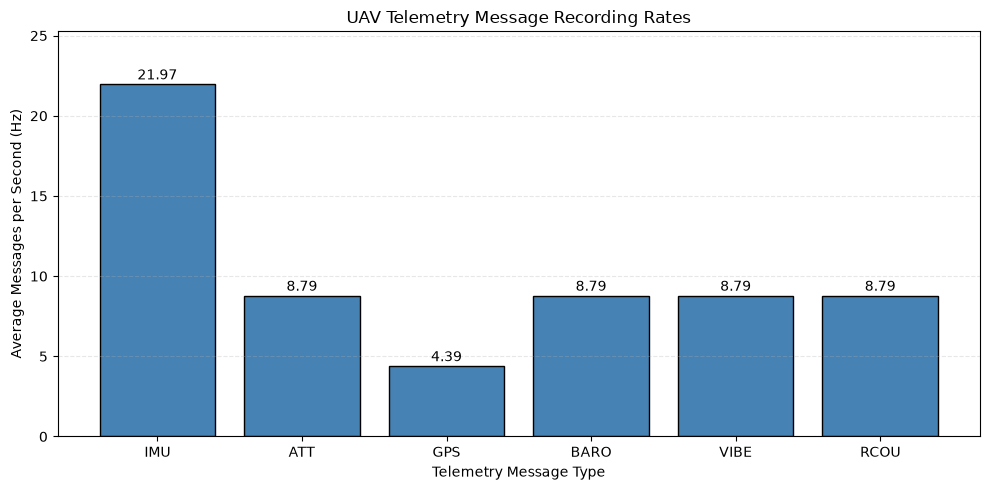

In [5]:

import matplotlib.pyplot as plt

# Telemetry message types to visualize
telemetry_types = [
    "IMU", "ATT", "GPS",
    "BARO", "VIBE", "RCOU"
]

# Calculate average message rates
rates = [
    message_counts[msg_type] / duration_seconds
    for msg_type in telemetry_types
]

# Create the graph
plt.figure(figsize=(10, 5))

bars = plt.bar(
    telemetry_types,
    rates,
    color="steelblue",
    edgecolor="black"
)

# Display values above bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.3,
        f"{height:.2f}",
        ha="center"
    )

plt.title("UAV Telemetry Message Recording Rates")
plt.xlabel("Telemetry Message Type")
plt.ylabel("Average Messages per Second (Hz)")
plt.ylim(0, max(rates) * 1.15)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
from pathlib import Path

figures_dir = Path(r"D:\Drone-research\outputs\figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "telemetry_message_rates.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [6]:
import numpy as np
from pymavlink import mavutil

log = mavutil.mavlink_connection(str(selected_log))

target_types = ["IMU", "ATT", "GPS", "BARO", "VIBE", "RCOU"]

timestamps = {name:[] for name in target_types}

while True:
    msg = log.recv_match()

    if msg is None:
        break

    msg_type = msg.get_type()

    if msg_type in timestamps:
        data = msg.to_dict()
        timestamp = data.get("TimeUS")

        if timestamp is not None:

            if msg_type == "IMU" and data.get("I") != 0:
                continue

            timestamps[msg_type].append(timestamp)

print(f"{'Type':<8} {'Median interval (ms)':<24} {'Median rate (Hz)'}")
print("-"* 55)

for msg_type, times in timestamps.items():
    times = np.sort(np.array(times, dtype=np.int64))

    intervals = np.diff(times)/ 1000
    intervals = intervals[intervals > 0]

    if len(intervals):
        median_interval = np.median(intervals)
        median_rate = 1000 / median_interval

        print(
            f"{msg_type:<8}"
            f"{median_interval:<24.2f} "
            f"{median_rate:.2f}"
        )
    else:
        print(f"{msg_type:>8} Insufficient timestamps")

            

Type     Median interval (ms)     Median rate (Hz)
-------------------------------------------------------
IMU     40.00                    25.00
ATT     100.00                   10.00
GPS     200.00                   5.00
BARO    100.00                   10.00
VIBE    100.00                   10.00
RCOU    100.00                   10.00


Total attitude records: 11437
     TimeUS  Roll  Pitch   Yaw    Time_s
0  23845225  1.24  -0.47  0.03  0.000000
1  23945401  1.24  -0.47  0.02  0.100176
2  24047397  1.24  -0.47  0.02  0.202172
3  24147365  1.24  -0.47  0.02  0.302140
4  24247300  1.25  -0.47  0.02  0.402075


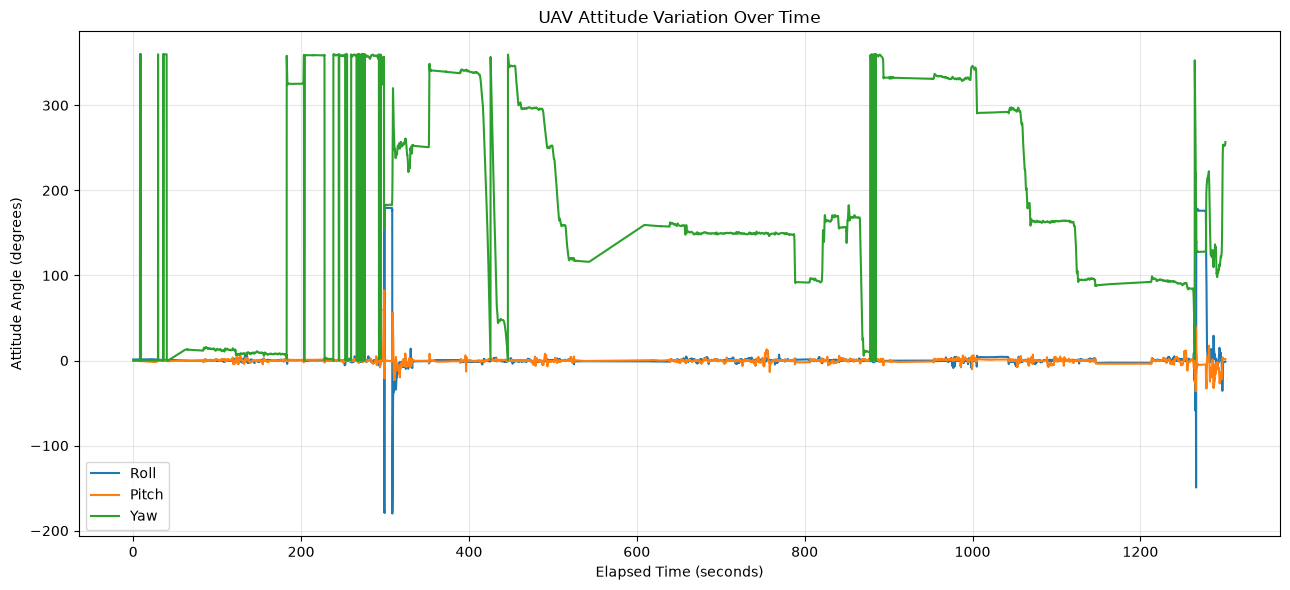

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from pymavlink import mavutil

log = mavutil.mavlink_connection(str(selected_log))

attitude_data = []

while True:
    msg = log.recv_match(type="ATT")

    if msg is None:
        break

    attitude_data.append({
        "TimeUS": msg.TimeUS,
        "Roll": msg.Roll,
        "Pitch": msg.Pitch,
        "Yaw": msg.Yaw
    })

att_df = pd.DataFrame(attitude_data)

att_df["Time_s"] = (
    att_df["TimeUS"] - att_df["TimeUS"].iloc[0]
) / 1_000_000

print("Total attitude records:" , len(att_df))
print(att_df.head())

# plotting the graph attitude against time 

plt.figure(figsize=(13, 6))

plt.plot(att_df["Time_s"], att_df["Roll"], label="Roll")
plt.plot(att_df["Time_s"], att_df["Pitch"], label="Pitch")
plt.plot(att_df["Time_s"], att_df["Yaw"], label="Yaw")

plt.title("UAV Attitude Variation Over Time")
plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Attitude Angle (degrees)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

        

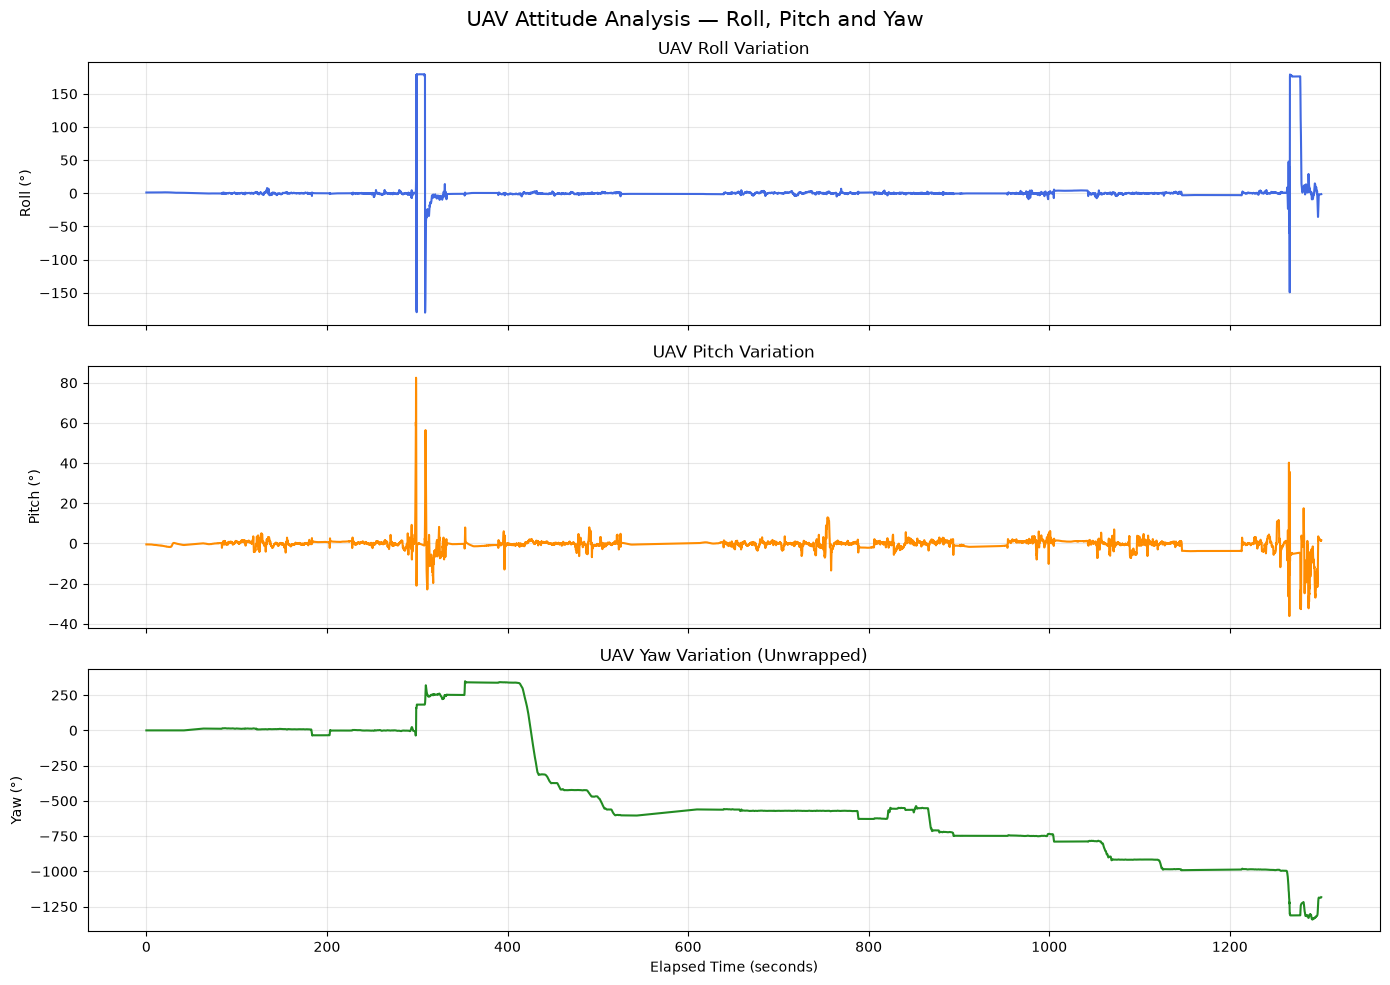

In [13]:

import numpy as np
import matplotlib.pyplot as plt

# Convert yaw to radians, unwrap, then return to degrees
yaw_unwrapped = np.rad2deg(
    np.unwrap(np.deg2rad(att_df["Yaw"].to_numpy()))
)

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 10),
    sharex=True
)

# Roll
axes[0].plot(
    att_df["Time_s"],
    att_df["Roll"],
    color="royalblue"
)
axes[0].set_ylabel("Roll (°)")
axes[0].set_title("UAV Roll Variation")
axes[0].grid(alpha=0.3)

# Pitch
axes[1].plot(
    att_df["Time_s"],
    att_df["Pitch"],
    color="darkorange"
)
axes[1].set_ylabel("Pitch (°)")
axes[1].set_title("UAV Pitch Variation")
axes[1].grid(alpha=0.3)

# Unwrapped yaw
axes[2].plot(
    att_df["Time_s"],
    yaw_unwrapped,
    color="forestgreen"
)
axes[2].set_ylabel("Yaw (°)")
axes[2].set_xlabel("Elapsed Time (seconds)")
axes[2].set_title("UAV Yaw Variation (Unwrapped)")
axes[2].grid(alpha=0.3)

plt.suptitle(
    "UAV Attitude Analysis — Roll, Pitch and Yaw",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [14]:

import pandas as pd
from pymavlink import mavutil

# Reopen the selected log
log = mavutil.mavlink_connection(str(selected_log))

arm_records = []

while True:
    msg = log.recv_match(type="ARM")

    if msg is None:
        break

    arm_records.append(msg.to_dict())

# Convert to DataFrame
arm_df = pd.DataFrame(arm_records)

# Convert timestamps to seconds relative
# to the start of our attitude data
if not arm_df.empty and "TimeUS" in arm_df.columns:
    arm_df["Time_s"] = (
        arm_df["TimeUS"] - att_df["TimeUS"].iloc[0]
    ) / 1_000_000

print("Total ARM records:", len(arm_df))
print(arm_df.to_string(index=False))


Total ARM records: 18
mavpackettype     TimeUS  ArmState  ArmChecks  Forced  Method      Time_s
          ARM   29647258         1          1       0       0    5.802033
          ARM   50547084         0          0       0       0   26.701859
          ARM   86147242         1          1       0       0   62.302017
          ARM  221647074         0          0       0       0  197.801849
          ARM  235647361         1          1       0       0  211.802136
          ARM  325376918         0          0       0      12  301.531693
          ARM  394047348         1          1       0       0  370.202123
          ARM  552247107         0          0       0       0  528.401882
          ARM  632647285         1          1       0       0  608.802060
          ARM  642547085         0          0       0      17  618.701860
          ARM  649247357         1          1       0       0  625.402132
          ARM  921047047         0          0       0       0  897.201822
          ARM  9

#### Do the extreme roll and pitch changes happen while the vehicle is armed or after it is disarmed? Let's visualise that.

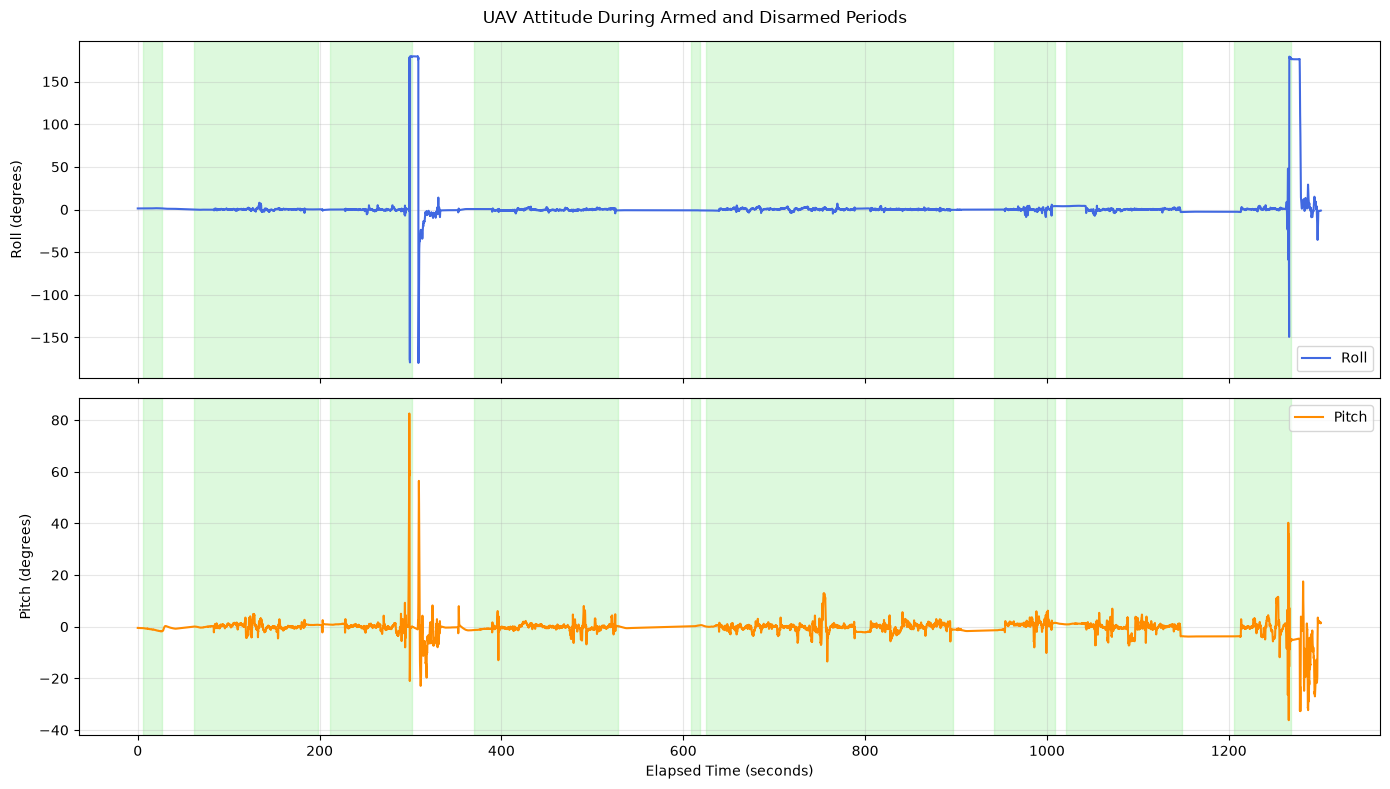

In [15]:

import matplotlib.pyplot as plt

# Identify complete armed intervals
armed_intervals = []
arm_start = None

for _, event in arm_df.sort_values("TimeUS").iterrows():
    if event["ArmState"] == 1:
        arm_start = event["Time_s"]

    elif event["ArmState"] == 0 and arm_start is not None:
        armed_intervals.append(
            (arm_start, event["Time_s"])
        )
        arm_start = None

# Create attitude plots
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

axes[0].plot(
    att_df["Time_s"],
    att_df["Roll"],
    color="royalblue",
    label="Roll"
)

axes[1].plot(
    att_df["Time_s"],
    att_df["Pitch"],
    color="darkorange",
    label="Pitch"
)

# Shade armed periods
for ax in axes:
    for start, end in armed_intervals:
        ax.axvspan(
            start,
            end,
            color="lightgreen",
            alpha=0.3
        )

    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Roll (degrees)")
axes[1].set_ylabel("Pitch (degrees)")
axes[1].set_xlabel("Elapsed Time (seconds)")

fig.suptitle(
    "UAV Attitude During Armed and Disarmed Periods"
)

plt.tight_layout()
plt.show()



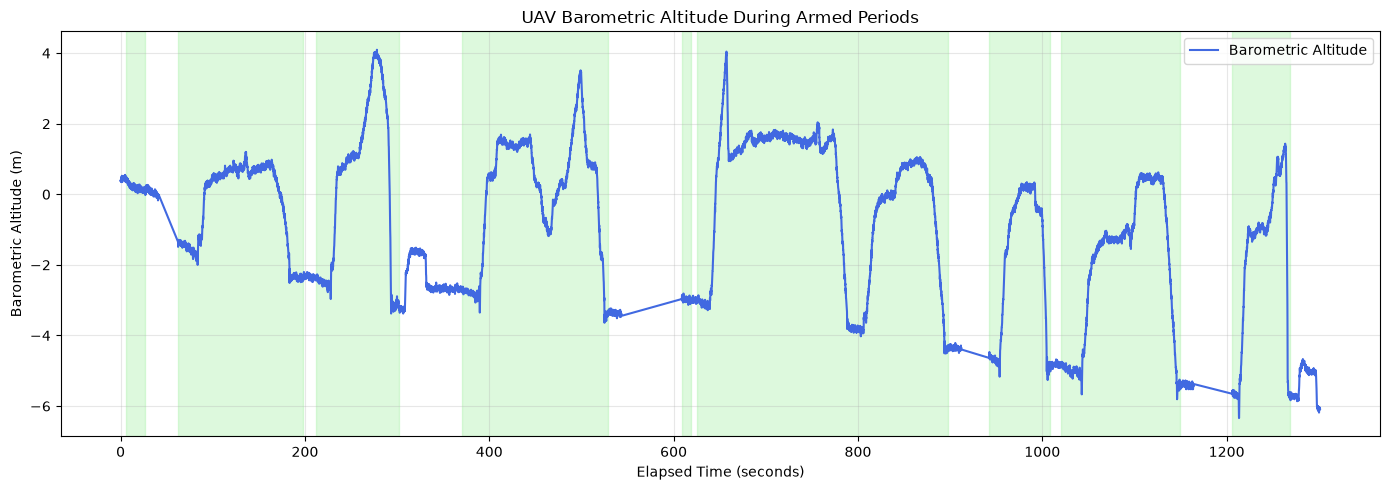

Minimum altitude: -6.34 m
Maximum altitude: 4.1 m


In [16]:

import pandas as pd
import matplotlib.pyplot as plt
from pymavlink import mavutil

# Read barometer data
log = mavutil.mavlink_connection(str(selected_log))

baro_records = []

while True:
    msg = log.recv_match(type="BARO")

    if msg is None:
        break

    data = msg.to_dict()

    # Use the primary barometer
    if data.get("I") == 0:
        baro_records.append({
            "TimeUS": data["TimeUS"],
            "Altitude": data["Alt"]
        })

baro_df = pd.DataFrame(baro_records)

# Use the same time reference as attitude data
baro_df["Time_s"] = (
    baro_df["TimeUS"] - att_df["TimeUS"].iloc[0]
) / 1_000_000

# Create altitude plot
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    baro_df["Time_s"],
    baro_df["Altitude"],
    color="royalblue",
    label="Barometric Altitude"
)

# Shade armed periods
for start, end in armed_intervals:
    ax.axvspan(
        start, end,
        color="lightgreen",
        alpha=0.3
    )

ax.set_title("UAV Barometric Altitude During Armed Periods")
ax.set_xlabel("Elapsed Time (seconds)")
ax.set_ylabel("Barometric Altitude (m)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Minimum altitude:", round(baro_df["Altitude"].min(), 2), "m")
print("Maximum altitude:", round(baro_df["Altitude"].max(), 2), "m")
